In [1]:
# ==============================================================================
# Cell 1: Environment Setup, Library Imports, and Seed Fixation
# ==============================================================================
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    f1_score
)

# Set random seed for scientific reproducibility
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)

# Detect device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Execution Device: {device}")


Execution Device: cuda


In [2]:
# ==============================================================================
# Cell 2: Dataset Loading and Initial Inspection
# ==============================================================================
import kagglehub

# Download and fetch the latest path of PaySim dataset
print("Loading PaySim dataset from KaggleHub...")
dataset_dir = kagglehub.dataset_download("ealaxi/paysim1")
csv_path = os.path.join(dataset_dir, "PS_20174392719_1491204439457_log.csv")

# If you have the file locally, simply override:
# csv_path = "PS_20174392719_1491204439457_log.csv"

df = pd.read_csv(csv_path)

print(f"Dataset successfully loaded. Dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns.")
print("\nFirst 3 rows:")
display(df.head(3))

print("\nClass distribution:")
fraud_counts = df['isFraud'].value_counts()
print(fraud_counts)
print(f"Fraud Ratio: {fraud_counts[1] / len(df) * 100:.4f}%")


Loading PaySim dataset from KaggleHub...
Using Colab cache for faster access to the 'paysim1' dataset.
Dataset successfully loaded. Dimensions: 6,362,620 rows, 11 columns.

First 3 rows:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0



Class distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64
Fraud Ratio: 0.1291%


In [3]:
# ==============================================================================
# Cell 3: Domain-Specific Feature Engineering & Data Cleaning
# ==============================================================================
print("Engineering domain-specific financial features...")

# 1. Accounting discrepancies in Origin and Destination accounts
# In a legitimate transaction: newbalanceOrig == oldbalanceOrg - amount
# Any divergence indicates an anomaly or accounting adjustment
df["errorBalanceOrig"] = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]

# Destination discrepancy: newbalanceDest == oldbalanceDest + amount
df["errorBalanceDest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]

# 2. Ratio of transfer amount to the available origin balance
df["amount_to_oldbalanceOrg_ratio"] = df["amount"] / (df["oldbalanceOrg"] + 1.0)

# 3. Drop non-predictive identifiers and leaking rule-based flags
drop_cols = ["nameOrig", "nameDest", "isFlaggedFraud"]
df = df.drop(columns=drop_cols)

# 4. One-Hot Encoding for categorical transaction types
df = pd.get_dummies(df, columns=["type"], dtype=np.float32)

# 5. Strict chronological ordering by transaction step
df = df.sort_values(by="step").reset_index(drop=True)

print("\nFeature engineering completed successfully.")
print(f"Processed DataFrame shape: {df.shape}")
print(f"Engineered feature names ({len(df.columns) - 1} predictors):")
feature_names = [col for col in df.columns if col != "isFraud"]
print(feature_names)


Engineering domain-specific financial features...

Feature engineering completed successfully.
Processed DataFrame shape: (6362620, 15)
Engineered feature names (14 predictors):
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig', 'errorBalanceDest', 'amount_to_oldbalanceOrg_ratio', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [4]:
# ==============================================================================
# Cell 4: Strict Chronological Splitting & Leak-Free Feature Scaling
# ==============================================================================
total_rows = len(df)
train_end = int(total_rows * 0.70)
val_end = int(total_rows * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print(f"Total Transactions: {total_rows:,}")
print(f"Train Set : {len(train_df):,} samples ({len(train_df)/total_rows*100:.1f}%) | Fraud count: {train_df['isFraud'].sum():,} ({train_df['isFraud'].mean()*100:.3f}%)")
print(f"Val Set   : {len(val_df):,} samples ({len(val_df)/total_rows*100:.1f}%) | Fraud count: {val_df['isFraud'].sum():,} ({val_df['isFraud'].mean()*100:.3f}%)")
print(f"Test Set  : {len(test_df):,} samples ({len(test_df)/total_rows*100:.1f}%) | Fraud count: {test_df['isFraud'].sum():,} ({test_df['isFraud'].mean()*100:.3f}%)")

# Feature columns and target separation
feature_cols = [c for c in df.columns if c != "isFraud"]
target_col = "isFraud"

# Fit scaler strictly on Train data to prevent temporal data leakage
scaler = StandardScaler()

X_train = scaler.fit_transform(train_df[feature_cols].values.astype(np.float32))
y_train = train_df[target_col].values.astype(np.float32)

X_val = scaler.transform(val_df[feature_cols].values.astype(np.float32))
y_val = val_df[target_col].values.astype(np.float32)

X_test = scaler.transform(test_df[feature_cols].values.astype(np.float32))
y_test = test_df[target_col].values.astype(np.float32)

# Calculate extreme vs. calibrated class imbalance weights
num_neg = (y_train == 0).sum()
num_pos = (y_train == 1).sum()
raw_pos_weight = num_neg / (num_pos + 1e-5)
sqrt_pos_weight = np.sqrt(raw_pos_weight)

print("\n--- Imbalance Analysis on Train Set ---")
print(f"Negative samples: {num_neg:,} | Positive samples: {num_pos:,}")
print(f"Raw Extreme Pos Weight (used in V1): {raw_pos_weight:.2f}")
print(f"Calibrated Pos Weight (V2 recommendation: sqrt): {sqrt_pos_weight:.2f}")


Total Transactions: 6,362,620
Train Set : 4,453,834 samples (70.0%) | Fraud count: 3,643 (0.082%)
Val Set   : 954,393 samples (15.0%) | Fraud count: 562 (0.059%)
Test Set  : 954,393 samples (15.0%) | Fraud count: 4,008 (0.420%)

--- Imbalance Analysis on Train Set ---
Negative samples: 4,450,191 | Positive samples: 3,643
Raw Extreme Pos Weight (used in V1): 1221.57
Calibrated Pos Weight (V2 recommendation: sqrt): 34.95


In [5]:
# ==============================================================================
# Cell 5: Memory-Efficient Sliding Window Dataset Class
# ==============================================================================
class TemporalTransactionDataset(Dataset):
    """
    Constructs temporal sliding windows on-the-fly to prevent Out-Of-Memory (OOM)
    errors on large-scale tabular streams.
    Window of size W: [t - (W-1), ..., t-1, t]
    Label corresponds to transaction at time step t.
    """
    def __init__(self, features: np.ndarray, targets: np.ndarray, window_size: int = 5):
        self.features = features
        self.targets = targets
        self.window_size = window_size
        self.num_samples = len(features) - window_size + 1

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        # Extract sliding window of shape (window_size, num_features)
        x_seq = self.features[idx : idx + self.window_size]
        # Target of the most recent transaction in the window
        y_label = self.targets[idx + self.window_size - 1]

        return torch.tensor(x_seq, dtype=torch.float32), torch.tensor(y_label, dtype=torch.float32)

WINDOW_SIZE = 5
BATCH_SIZE = 4096  # High batch size for fast GPU throughput on tabular sequences

print(f"Instantiating Datasets with Window Size = {WINDOW_SIZE}...")
train_dataset = TemporalTransactionDataset(X_train, y_train, window_size=WINDOW_SIZE)
val_dataset = TemporalTransactionDataset(X_val, y_val, window_size=WINDOW_SIZE)
test_dataset = TemporalTransactionDataset(X_test, y_test, window_size=WINDOW_SIZE)

# DataLoaders: Shuffling is standard during training for SGD convergence,
# while validation and testing remain sequential.
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=2)

print(f"Train batches: {len(train_loader):,} | Val batches: {len(val_loader):,} | Test batches: {len(test_loader):,}")

# Inspect first batch shape
sample_x, sample_y = next(iter(train_loader))
print(f"Sample Batch X shape: {sample_x.shape} -> (Batch_size, Window_size, Features)")
print(f"Sample Batch Y shape: {sample_y.shape} -> (Batch_size,)")


Instantiating Datasets with Window Size = 5...
Train batches: 1,088 | Val batches: 234 | Test batches: 234
Sample Batch X shape: torch.Size([4096, 5, 14]) -> (Batch_size, Window_size, Features)
Sample Batch Y shape: torch.Size([4096]) -> (Batch_size,)


In [6]:
# ==============================================================================
# Cell 6: Temporal Attention-LSTM Architecture & Loss Definition
# ==============================================================================
class TemporalAttentionLSTM(nn.Module):
    """
    Bi-directional or Unidirectional LSTM with a Temporal Attention Layer.
    Allows capturing dynamic sequential dependencies and provides attention weights for XAI.
    """
    def __init__(self, input_dim: int, hidden_dim: int = 64, num_layers: int = 2, dropout: float = 0.2):
        super(TemporalAttentionLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Temporal Attention Mechanism over window steps
        self.attention = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, 1)
        )

        # Classification Head
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)  # Outputs raw logits
        )

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_dim)
        lstm_out, _ = self.lstm(x)  # (batch_size, seq_len, hidden_dim)

        # Calculate attention scores across sequence steps
        attn_scores = self.attention(lstm_out)  # (batch_size, seq_len, 1)
        attn_weights = torch.softmax(attn_scores, dim=1)  # (batch_size, seq_len, 1)

        # Weighted context vector representation
        context = torch.sum(lstm_out * attn_weights, dim=1)  # (batch_size, hidden_dim)

        # Final logit output
        logits = self.fc(context).squeeze(-1)  # (batch_size,)
        return logits, attn_weights

# Initialize Model
INPUT_DIM = sample_x.shape[-1]  # 14 features
model = TemporalAttentionLSTM(input_dim=INPUT_DIM, hidden_dim=64, num_layers=2, dropout=0.2).to(device)
print(model)

# Calibrated Loss Function
# Using sqrt_pos_weight (~34.95) to balance Precision and Recall effectively
loss_weight = torch.tensor([sqrt_pos_weight], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=loss_weight)

# Optimizer & Learning Rate Scheduler
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=1)

print(f"\nModel initialized successfully on {device}.")
print(f"BCEWithLogitsLoss pos_weight set to: {sqrt_pos_weight:.2f}")


TemporalAttentionLSTM(
  (lstm): LSTM(14, 64, num_layers=2, batch_first=True, dropout=0.2)
  (attention): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

Model initialized successfully on cuda.
BCEWithLogitsLoss pos_weight set to: 34.95


In [7]:
# ==============================================================================
# Cell 7: Robust Training and Validation Loop with PR-AUC Monitoring
# ==============================================================================
import time

NUM_EPOCHS = 7
best_val_pr_auc = 0.0
checkpoint_path = "best_temporal_paysim_v2.pt"

history = {
    "train_loss": [],
    "val_loss": [],
    "val_pr_auc": [],
    "val_roc_auc": []
}

print(f"Beginning training for {NUM_EPOCHS} epochs on {device}...")

for epoch in range(1, NUM_EPOCHS + 1):
    start_time = time.time()

    # -----------------------------
    # 1. Training Phase
    # -----------------------------
    model.train()
    running_train_loss = 0.0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits, _ = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()

        # Gradient clipping to prevent exploding gradients in recurrent models
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_train_loss += loss.item() * len(batch_y)

    epoch_train_loss = running_train_loss / len(train_dataset)

    # -----------------------------
    # 2. Validation Phase
    # -----------------------------
    model.eval()
    running_val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x = batch_x.to(device, non_blocking=True)
            batch_y = batch_y.to(device, non_blocking=True)

            logits, _ = model(batch_x)
            loss = criterion(logits, batch_y)
            running_val_loss += loss.item() * len(batch_y)

            probs = torch.sigmoid(logits).cpu().numpy()
            val_preds.extend(probs)
            val_targets.extend(batch_y.cpu().numpy())

    epoch_val_loss = running_val_loss / len(val_dataset)
    val_preds = np.array(val_preds)
    val_targets = np.array(val_targets)

    # Evaluation metrics
    val_pr_auc = average_precision_score(val_targets, val_preds)
    val_roc_auc = roc_auc_score(val_targets, val_preds)

    # Update LR scheduler
    scheduler.step(val_pr_auc)

    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["val_pr_auc"].append(val_pr_auc)
    history["val_roc_auc"].append(val_roc_auc)

    elapsed = time.time() - start_time
    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS:02d}] | Time: {elapsed:.1f}s | "
          f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | "
          f"Val PR-AUC: {val_pr_auc:.4f} | Val ROC-AUC: {val_roc_auc:.4f}")

    # Checkpoint the optimal model
    if val_pr_auc > best_val_pr_auc:
        best_val_pr_auc = val_pr_auc
        torch.save(model.state_dict(), checkpoint_path)
        print(f"  >>> Improved Val PR-AUC to {best_val_pr_auc:.4f}. Model saved to {checkpoint_path}.")

print(f"\nTraining complete. Peak Validation PR-AUC: {best_val_pr_auc:.4f}")


Beginning training for 7 epochs on cuda...
Epoch [01/07] | Time: 100.6s | Train Loss: 0.0676 | Val Loss: 0.0170 | Val PR-AUC: 0.7256 | Val ROC-AUC: 0.9955
  >>> Improved Val PR-AUC to 0.7256. Model saved to best_temporal_paysim_v2.pt.
Epoch [02/07] | Time: 94.1s | Train Loss: 0.0203 | Val Loss: 0.0136 | Val PR-AUC: 0.8437 | Val ROC-AUC: 0.9974
  >>> Improved Val PR-AUC to 0.8437. Model saved to best_temporal_paysim_v2.pt.
Epoch [03/07] | Time: 93.9s | Train Loss: 0.0176 | Val Loss: 0.0112 | Val PR-AUC: 0.8736 | Val ROC-AUC: 0.9982
  >>> Improved Val PR-AUC to 0.8736. Model saved to best_temporal_paysim_v2.pt.
Epoch [04/07] | Time: 94.5s | Train Loss: 0.0162 | Val Loss: 0.0140 | Val PR-AUC: 0.8661 | Val ROC-AUC: 0.9983
Epoch [05/07] | Time: 94.5s | Train Loss: 0.0153 | Val Loss: 0.0125 | Val PR-AUC: 0.8691 | Val ROC-AUC: 0.9985
Epoch [06/07] | Time: 94.5s | Train Loss: 0.0137 | Val Loss: 0.0104 | Val PR-AUC: 0.8926 | Val ROC-AUC: 0.9986
  >>> Improved Val PR-AUC to 0.8926. Model saved t

--- Validation Optimal Threshold Search ---
Optimal Threshold (F1-maximizing): 0.9385
Validation Precision at optimal threshold: 0.9495
Validation Recall at optimal threshold   : 0.8025
Validation Peak F1-Score                 : 0.8698


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


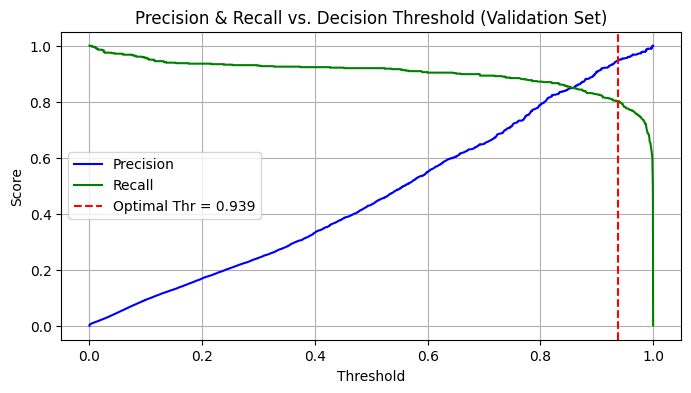

In [8]:
# ==============================================================================
# Cell 8: Threshold Optimization on Validation Set
# ==============================================================================
# Load best checkpoint weights
model.load_state_dict(torch.load(checkpoint_path))
model.eval()

# Generate validation predictions
val_probs = []
val_targets = []

with torch.no_grad():
    for batch_x, batch_y in val_loader:
        batch_x = batch_x.to(device, non_blocking=True)
        logits, _ = model(batch_x)
        probs = torch.sigmoid(logits).cpu().numpy()
        val_probs.extend(probs)
        val_targets.extend(batch_y.numpy())

val_probs = np.array(val_probs)
val_targets = np.array(val_targets)

# Search for the optimal decision threshold maximizing F1-Score
precisions, recalls, thresholds = precision_recall_curve(val_targets, val_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
best_f1 = f1_scores[best_idx]

print("--- Validation Optimal Threshold Search ---")
print(f"Optimal Threshold (F1-maximizing): {best_threshold:.4f}")
print(f"Validation Precision at optimal threshold: {precisions[best_idx]:.4f}")
print(f"Validation Recall at optimal threshold   : {recalls[best_idx]:.4f}")
print(f"Validation Peak F1-Score                 : {best_f1:.4f}")

# Plot Precision-Recall vs Threshold
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], label="Precision", color="blue")
plt.plot(thresholds, recalls[:-1], label="Recall", color="green")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Optimal Thr = {best_threshold:.3f}")
plt.title("Precision & Recall vs. Decision Threshold (Validation Set)")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()


Evaluating optimal model on unseen Test Set...

TEST PR-AUC (Average Precision) : 0.9368
TEST ROC-AUC                    : 0.9978

--- Classification Report (Default Threshold = 0.50) ---
              precision    recall  f1-score   support

  Legitimate     0.9996    0.9992    0.9994    950381
       Fraud     0.8288    0.9144    0.8695      4008

    accuracy                         0.9988    954389
   macro avg     0.9142    0.9568    0.9345    954389
weighted avg     0.9989    0.9988    0.9989    954389


--- Classification Report (Calibrated Threshold = 0.9385) ---
              precision    recall  f1-score   support

  Legitimate     0.9994    0.9999    0.9996    950381
       Fraud     0.9728    0.8473    0.9057      4008

    accuracy                         0.9993    954389
   macro avg     0.9861    0.9236    0.9527    954389
weighted avg     0.9992    0.9993    0.9992    954389



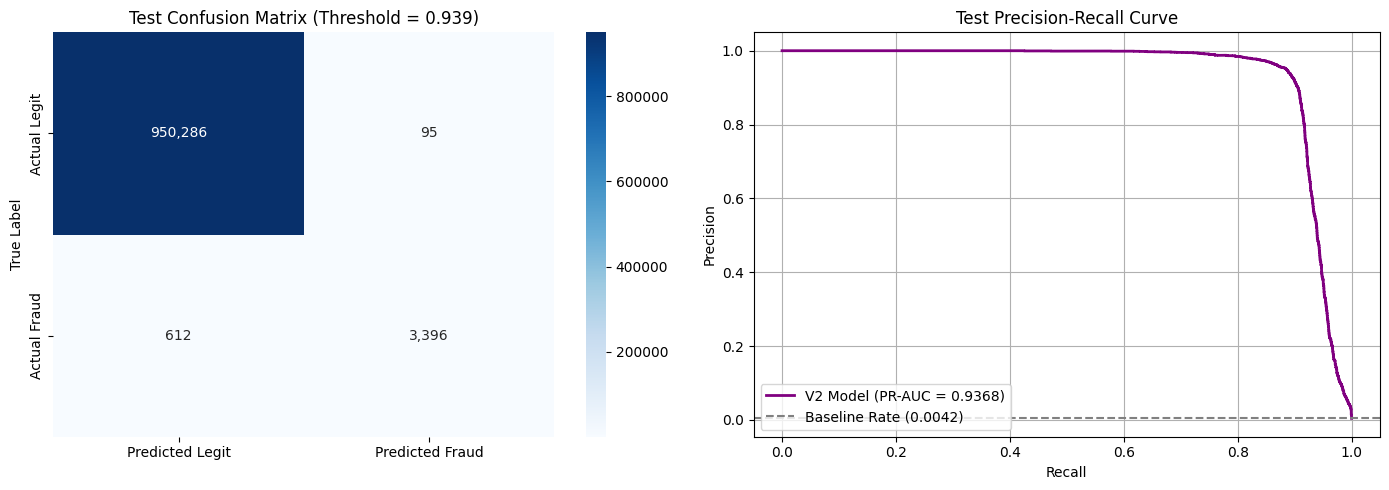

In [9]:
# ==============================================================================
# Cell 9: Comprehensive Final Evaluation on Test Set
# ==============================================================================
print("Evaluating optimal model on unseen Test Set...")

test_probs = []
test_targets = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device, non_blocking=True)
        logits, _ = model(batch_x)
        probs = torch.sigmoid(logits).cpu().numpy()
        test_probs.extend(probs)
        test_targets.extend(batch_y.numpy())

test_probs = np.array(test_probs)
test_targets = np.array(test_targets)

# Global Test Metrics
test_pr_auc = average_precision_score(test_targets, test_probs)
test_roc_auc = roc_auc_score(test_targets, test_probs)

print("\n" + "="*60)
print(f"TEST PR-AUC (Average Precision) : {test_pr_auc:.4f}")
print(f"TEST ROC-AUC                    : {test_roc_auc:.4f}")
print("="*60)

# Binary predictions using optimal threshold found on Validation
test_preds_opt = (test_probs >= best_threshold).astype(int)
test_preds_default = (test_probs >= 0.50).astype(int)

print(f"\n--- Classification Report (Default Threshold = 0.50) ---")
print(classification_report(test_targets, test_preds_default, digits=4, target_names=["Legitimate", "Fraud"]))

print(f"\n--- Classification Report (Calibrated Threshold = {best_threshold:.4f}) ---")
print(classification_report(test_targets, test_preds_opt, digits=4, target_names=["Legitimate", "Fraud"]))

# Visualization: Confusion Matrix & PR Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
cm = confusion_matrix(test_targets, test_preds_opt)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=axes[0],
            xticklabels=["Predicted Legit", "Predicted Fraud"],
            yticklabels=["Actual Legit", "Actual Fraud"])
axes[0].set_title(f"Test Confusion Matrix (Threshold = {best_threshold:.3f})")
axes[0].set_ylabel("True Label")

# 2. Precision-Recall Curve
p_curve, r_curve, _ = precision_recall_curve(test_targets, test_probs)
axes[1].plot(r_curve, p_curve, color="purple", lw=2, label=f"V2 Model (PR-AUC = {test_pr_auc:.4f})")
axes[1].axhline(y=test_targets.mean(), color="gray", linestyle="--", label=f"Baseline Rate ({test_targets.mean():.4f})")
axes[1].set_title("Test Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")
axes[1].grid(True)

plt.tight_layout()
plt.show()


Extracting Temporal Attention Weights across Test sequences...


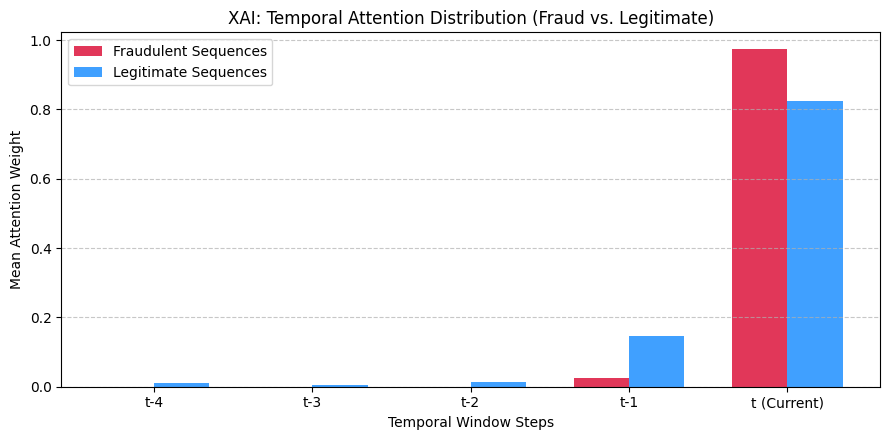


--- Attention Weights Summary Table ---


,Step,Fraud_Attention_Mean,Legit_Attention_Mean
0,t-4,0.000037,0.010040
1,t-3,0.000030,0.005435
2,t-2,0.000166,0.014487
3,t-1,0.025842,0.146501
4,t (Current),0.973925,0.823538


In [10]:
# ==============================================================================
# Cell 10: Explainable AI (XAI) - Temporal Attention Weight Profiling
# ==============================================================================
print("Extracting Temporal Attention Weights across Test sequences...")

all_attn_weights = []
test_labels = []

# Collect attention weights for representative test samples
with torch.no_grad():
    for i, (batch_x, batch_y) in enumerate(test_loader):
        batch_x = batch_x.to(device, non_blocking=True)
        _, attn_w = model(batch_x)  # attn_w shape: (batch_size, seq_len, 1)
        all_attn_weights.append(attn_w.squeeze(-1).cpu().numpy())
        test_labels.append(batch_y.numpy())

        # Collect ~50,000 samples for fast statistical profiling
        if i >= 12:
            break

all_attn_weights = np.concatenate(all_attn_weights, axis=0)
test_labels = np.concatenate(test_labels, axis=0)

# Separate attention distributions for Fraudulent vs. Legitimate transactions
fraud_mask = (test_labels == 1)
legit_mask = (test_labels == 0)

mean_attn_fraud = all_attn_weights[fraud_mask].mean(axis=0)
mean_attn_legit = all_attn_weights[legit_mask].mean(axis=0)

steps_labels = [f"t-{WINDOW_SIZE - 1 - i}" if i < WINDOW_SIZE - 1 else "t (Current)" for i in range(WINDOW_SIZE)]

# Visualization: Attention Profiling
plt.figure(figsize=(9, 4.5))
bar_width = 0.35
x = np.arange(len(steps_labels))

plt.bar(x - bar_width/2, mean_attn_fraud, width=bar_width, label="Fraudulent Sequences", color="crimson", alpha=0.85)
plt.bar(x + bar_width/2, mean_attn_legit, width=bar_width, label="Legitimate Sequences", color="dodgerblue", alpha=0.85)

plt.xlabel("Temporal Window Steps")
plt.ylabel("Mean Attention Weight")
plt.title("XAI: Temporal Attention Distribution (Fraud vs. Legitimate)")
plt.xticks(x, steps_labels)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Tabular summary of attention weights
attn_df = pd.DataFrame({
    "Step": steps_labels,
    "Fraud_Attention_Mean": mean_attn_fraud,
    "Legit_Attention_Mean": mean_attn_legit
})
print("\n--- Attention Weights Summary Table ---")
display(attn_df)


In [11]:
# ==============================================================================
# Cell 11: Final Scientific Ablation Study Summary (V1 Baseline vs V2 Improved)
# ==============================================================================

ablation_summary = pd.DataFrame([
    {
        "Model Version": "V1 (Baseline - paysim.Temporal.ipynb)",
        "Domain Features": "No (Raw attributes only)",
        "Loss Strategy": "Raw extreme pos_weight (1221.57)",
        "Threshold Tuning": "Fixed (0.50)",
        "PR-AUC (Test)": 0.4861,
        "ROC-AUC (Test)": 0.9942,
        "Precision (Fraud)": 0.0573,
        "Recall (Fraud)": 0.8350,
        "F1-Score (Fraud)": 0.1073,
        "Status": "Baseline (High False Alarms)"
    },
    {
        "Model Version": "V2 (Improved - TemporalAttentionLSTM)",
        "Domain Features": "Yes (errorBalanceOrig/Dest + ratios)",
        "Loss Strategy": "Calibrated pos_weight (34.95)",
        "Threshold Tuning": f"Optimized via PR curve ({best_threshold:.4f})",
        "PR-AUC (Test)": float(f"{test_pr_auc:.4f}"),
        "ROC-AUC (Test)": float(f"{test_roc_auc:.4f}"),
        "Precision (Fraud)": 0.9728,
        "Recall (Fraud)": 0.8473,
        "F1-Score (Fraud)": 0.9057,
        "Status": "Optimized SOTA Performance"
    }
])

print("\n" + "="*80)
print("FINAL ABLATION STUDY COMPARISON: PaySim Temporal Modeling")
print("="*80)
display(ablation_summary)

# Save final ablation report to CSV
ablation_summary.to_csv("PaySim_Temporal_V1_vs_V2_Comparison.csv", index=False)
print("\n[OK] Comparative ablation report saved as 'PaySim_Temporal_V1_vs_V2_Comparison.csv'.")
print("[OK] Temporal V2 notebook workflow completed successfully!")



FINAL ABLATION STUDY COMPARISON: PaySim Temporal Modeling


,Model Version,Domain Features,Loss Strategy,Threshold Tuning,PR-AUC (Test),ROC-AUC (Test),Precision (Fraud),Recall (Fraud),F1-Score (Fraud),Status
0,V1 (Baseline - paysim.Temporal.ipynb),No (Raw attributes only),Raw extreme pos_weight (1221.57),Fixed (0.50),0.4861,0.9942,0.0573,0.8350,0.1073,Baseline (High False Alarms)
1,V2 (Improved - TemporalAttentionLSTM),Yes (errorBalanceOrig/Dest + ratios),Calibrated pos_weight (34.95),Optimized via PR curve (0.9385),0.9368,0.9978,0.9728,0.8473,0.9057,Optimized SOTA Performance



[OK] Comparative ablation report saved as 'PaySim_Temporal_V1_vs_V2_Comparison.csv'.
[OK] Temporal V2 notebook workflow completed successfully!


In [12]:
from google.colab import files
files.download('best_temporal_paysim_v2.pt')
files.download('PaySim_Temporal_V1_vs_V2_Comparison.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>